In [38]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import time
from torchsummary import summary
from sklearn.preprocessing import StandardScaler

print("CUDA 是否可用:", torch.cuda.is_available())
print("显卡名称:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "无")

CUDA 是否可用: False
显卡名称: 无


In [32]:
def preprocessing():
    # 1.导入数据集
    data = pd.read_csv('./data/手机价格预测.csv')
    # 提取特征数据
    x, y = data.iloc[:, :-1], data.iloc[:, -1]
    # 转换数据类型
    x = x.astype(np.float32)
    # 切割数据
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0, stratify=y)
    # 数据标准化
    transfer = StandardScaler()
    x_train = transfer.fit_transform(x_train)
    x_test = transfer.transform(x_test)
    # 封装成张量数据集
    train_dataset = TensorDataset(torch.tensor(x_train), torch.tensor(y_train.values))
    test_dataset = TensorDataset(torch.tensor(x_test), torch.tensor(y_test.values))
    # 记录 输入特征数 与 分类数量
    input_dim = x.shape[1]
    output_dim = len(np.unique(y))

    print(f'输入特征数: {input_dim}')
    print(f'分类数量: {output_dim}')

    return train_dataset, test_dataset, input_dim, output_dim

In [33]:
# 2.搭建神经网络
class PhonePriceModel(nn.Module):
    # 初始化神经网络
    def __init__(self, input_dim, output_dim):
        # 初始化父类成员
        super().__init__()
        # 隐藏层1
        self.linear1 = nn.Linear(input_dim, 256)
        # 隐藏层2
        self.linear2 = nn.Linear(256, 128)
        # 输出层
        self.output = nn.Linear(128, output_dim)

    # 前向传播
    def forward(self, x):
        # 隐藏层1
        x = torch.relu(self.linear1(x))
        # 隐藏层2
        x = torch.relu(self.linear2(x))
        # 输出层
        x = self.output(x)

        return x


In [34]:
# 3.模型训练
def train(train_dataset, input_dim, output_dim):
    # 加载数据集
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    # 创建神经网络
    model = PhonePriceModel(input_dim, output_dim)
    # 损失函数
    criterion = nn.CrossEntropyLoss()
    # 优化器
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    # 训练轮数
    epochs = 50
    # 记录loss值
    loss_list = []

    # 更改模型状态
    model.train()
    # 模型训练
    start_time = time.time()  # 记录开始时间
    for epoch in range(epochs):
        total_loss = 0  # 记录当前轮次的总loss值
        for x, y in train_loader:
            optimizer.zero_grad()  # 梯度清零
            y_pred = model(x)  # 模型预测
            loss = criterion(y_pred, y)  # 损失计算
            loss.backward()  # 反向传播
            optimizer.step()  # 优化器更新
            total_loss += loss.item()  # 累加批次loss值
        loss_list.append(total_loss / len(train_loader))  # 记录当前轮次的平均loss值
        print(f'epoch: {epoch + 1}, loss: {total_loss / len(train_loader):.4f}, time: {time.time() - start_time:.2f}s')

    # 保存模型
    torch.save(model.state_dict(), './model/phonePrice.pth')

    # 训练可视化
    plt.plot(loss_list)
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.grid(alpha=0.3)
    plt.show()

In [35]:
# 4.模型测试
def evaluate(test_dataset, input_dim, output_dim):
    # 创建模型对象
    model = PhonePriceModel(input_dim, output_dim)
    # 加载模型参数
    model.load_state_dict(torch.load('./model/phonePrice.pth'))
    # 加载测试集
    test_loader = DataLoader(test_dataset, batch_size=8, shuffle=True)

    correct_num = 0  # 统计总正确个数
    model.eval()  # 切换模型状态
    # 模型评估
    for x, y in test_loader:
        y_pred = torch.argmax(model(x), dim=1)
        # print(y_pred)
        correct_num += (y_pred == y).sum()

    print(f'准确率: {correct_num * 100 / len(test_dataset):.2f}%')


输入特征数: 20
分类数量: 4
epoch: 1, loss: 0.5757, time: 0.14s
epoch: 2, loss: 0.3353, time: 0.30s
epoch: 3, loss: 0.2733, time: 0.45s
epoch: 4, loss: 0.1942, time: 0.58s
epoch: 5, loss: 0.1762, time: 0.74s
epoch: 6, loss: 0.1171, time: 0.88s
epoch: 7, loss: 0.1827, time: 1.02s
epoch: 8, loss: 0.1849, time: 1.27s
epoch: 9, loss: 0.1272, time: 1.55s
epoch: 10, loss: 0.1115, time: 1.78s
epoch: 11, loss: 0.0983, time: 2.02s
epoch: 12, loss: 0.1049, time: 2.22s
epoch: 13, loss: 0.1726, time: 2.44s
epoch: 14, loss: 0.1445, time: 2.70s
epoch: 15, loss: 0.0995, time: 2.94s
epoch: 16, loss: 0.0237, time: 3.18s
epoch: 17, loss: 0.0192, time: 3.42s
epoch: 18, loss: 0.0175, time: 3.69s
epoch: 19, loss: 0.0393, time: 3.99s
epoch: 20, loss: 0.3872, time: 4.26s
epoch: 21, loss: 0.1342, time: 4.47s
epoch: 22, loss: 0.0422, time: 4.71s
epoch: 23, loss: 0.0118, time: 4.87s
epoch: 24, loss: 0.0439, time: 5.16s
epoch: 25, loss: 0.0527, time: 5.30s
epoch: 26, loss: 0.1146, time: 5.53s
epoch: 27, loss: 0.0498, time

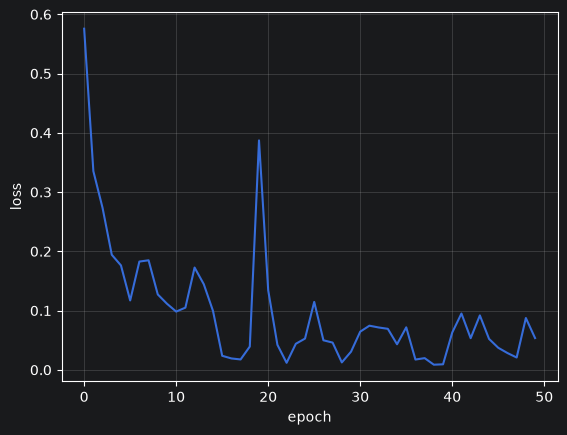

准确率: 88.25%


In [36]:
# 5.测试
train_dataset, test_dataset, input_dim, output_dim = preprocessing()
model = PhonePriceModel(input_dim, output_dim)
# summary(model, input_size=(input_dim,))
train(train_dataset, input_dim, output_dim)
evaluate(test_dataset, input_dim, output_dim)